In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay

# Same seed and folder as the EDA notebook
SEED = 42
np.random.seed(SEED)

In [2]:
OUT = "paraphrase"
os.makedirs(OUT + "/preds", exist_ok=True)
os.makedirs(OUT + "/models", exist_ok=True)
os.makedirs(OUT + "/figures", exist_ok=True)

## 1. Load the clean data

We load the CSVs saved in the EDA notebook so every model uses exactly the same data.

In [3]:
data = {}
for ds in ["mrpc", "qqp", "paws"]:
    data[ds] = {}
    for split in ["train", "dev", "test"]:
        # keep_default_na=False stops pandas from turning text like "NA" or "null" into missing values
        df = pd.read_csv(f"{OUT}/splits/{ds}_{split}.csv", keep_default_na=False)
        df["sentence1"] = df["sentence1"].astype(str)
        df["sentence2"] = df["sentence2"].astype(str)
        data[ds][split] = df

In [4]:
# Check that the sizes and % paraphrase should match the final table in the EDA notebook
for ds in data:
    for split, df in data[ds].items():
        n_pairs = len(df)
        pct_para = df["label"].mean() * 100   # labels are 0 or 1, so the mean is the fraction of paraphrases
        print(f"{ds}_{split}: {n_pairs} pairs, {pct_para:.1f}% paraphrase")

mrpc_train: 3301 pairs, 67.8% paraphrase
mrpc_dev: 367 pairs, 64.6% paraphrase
mrpc_test: 408 pairs, 68.4% paraphrase
qqp_train: 36000 pairs, 36.7% paraphrase
qqp_dev: 4000 pairs, 35.8% paraphrase
qqp_test: 5000 pairs, 36.7% paraphrase
paws_train: 49259 pairs, 44.1% paraphrase
paws_dev: 7983 pairs, 44.2% paraphrase
paws_test: 8000 pairs, 44.2% paraphrase


In [5]:
# show the full sentences
pd.set_option("display.max_colwidth", None)

# print a few examples from each training set
for ds in ["mrpc", "qqp", "paws"]:
    print(ds.upper(), "train examples:")

    train = data[ds]["train"]

    # pick 2 paraphrase and 2 non-paraphrase pairs
    para = train[train["label"] == 1].head(2)
    not_para = train[train["label"] == 0].head(2)

    examples = pd.concat([para, not_para])
    display(examples)

MRPC train examples:


,sentence1,sentence2,label
0,"Amrozi accused his brother , whom he called "" the witness "" , of deliberately distorting his evidence .","Referring to him as only "" the witness "" , Amrozi accused his brother of deliberately distorting his evidence .",1
2,"They had published an advertisement on the Internet on June 10 , offering the cargo for sale , he added .","On June 10 , the ship 's owners had published an advertisement on the Internet , offering the explosives for sale .",1
1,Yucaipa owned Dominick 's before selling the chain to Safeway in 1998 for $ 2.5 billion .,Yucaipa bought Dominick 's in 1995 for $ 693 million and sold it to Safeway for $ 1.8 billion in 1998 .,0
3,"Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .","Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .",0


QQP train examples:


,sentence1,sentence2,label
0,What are the major human caused threats to biodiversity? How can we solve this threats?,What are human impacts on biodiversity?,1
6,What are best websites for booking tours across the globe?,What are the best websites for booking tours around the world?,1
1,How does the reserve in a petrol tank of a bike work? What actually happens when we switch the knob to reserve?,Why are motorcycles so much louder than cars or buses?,0
2,What is a good book about data-structures and algorithms in javascript?,What are the best books on algorithms and data structures?,0


PAWS train examples:


,sentence1,sentence2,label
1,The NBA season of 1975 -- 76 was the 30th season of the National Basketball Association .,The 1975 -- 76 season of the National Basketball Association was the 30th season of the NBA .,1
3,"When comparable rates of flow can be maintained , the results are high .",The results are high when comparable flow rates can be maintained .,1
0,"In Paris , in October 1560 , he secretly met the English ambassador , Nicolas Throckmorton , asking him for a passport to return to England through Scotland .","In October 1560 , he secretly met with the English ambassador , Nicolas Throckmorton , in Paris , and asked him for a passport to return to Scotland through England .",0
2,"There are also specific discussions , public profile debates and project discussions .","There are also public discussions , profile specific discussions , and project discussions .",0


## 2. Features
Each sentence is turned into a TF-IDF vector, where rare words get more weight than common words like "the". The vocabulary is learned from the training sentences only.

For each pair we then build these features:
- **cosine similarity** of the two TF-IDF vectors
- **Jaccard overlap** (same as in the EDA)
- **length difference** in words
- **|A − B|**: words that appear in only one sentence
- **A × B**: words that appear in both sentences

In [6]:
# Jaccard overlap = shared words / all unique words in the pair
def jaccard(s1, s2):
    w1 = set(re.findall(r"\w+", s1.lower()))
    w2 = set(re.findall(r"\w+", s2.lower()))
    
    # Avoid division by zero when both sentences are empty
    if len(w1 | w2) == 0:
        return 0.0
    return len(w1 & w2) / len(w1 | w2)

In [7]:
def make_vectorizer(train_df):
    # Single words and word pairs, ignore words seen only once,
    # and use log counts so repeated words don't dominate
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

    # Learn the vocabulary from both columns of the training data only
    all_sentences = pd.concat([train_df["sentence1"], train_df["sentence2"]])
    vec.fit(all_sentences)
    return vec

In [8]:
def build_features(vec, df):
    # Turn each sentence into a TF-IDF vector
    A = vec.transform(df["sentence1"])
    B = vec.transform(df["sentence2"])

    # TF-IDF vectors have length 1, so their dot product is the cosine similarity
    cosine = np.asarray(A.multiply(B).sum(axis=1)).ravel()

    # Jaccard overlap for each pair
    jac = np.array([jaccard(s1, s2) for s1, s2 in zip(df["sentence1"], df["sentence2"])])

    # Difference in number of words, divided by 10 so it's on a similar scale to the others
    len1 = df["sentence1"].str.split().str.len()
    len2 = df["sentence2"].str.split().str.len()
    len_diff = np.abs(len1 - len2).values / 10

    # Put the 3 single-number features side by side
    simple = csr_matrix(np.column_stack([cosine, jac, len_diff]))

    # Word-level features: words in only one sentence, and words in both
    diff = abs(A - B)
    both = A.multiply(B)

    # Join everything into one big sparse matrix (mostly zeros, so this saves memory)
    X = hstack([simple, diff, both]).tocsr()
    return X

In [9]:
# Display the features for a few QQP pairs
vec = make_vectorizer(data["qqp"]["train"])
sample = data["qqp"]["train"].head(5)

X = build_features(vec, sample)
print("Feature matrix shape:", X.shape)   # (number of pairs, number of features)

# show the 3 simple features next to the sentences
show = sample[["sentence1", "sentence2", "label"]].copy()
show["cosine"] = X[:, 0].toarray().round(3)
show["jaccard"] = X[:, 1].toarray().round(3)
show["len_diff"] = X[:, 2].toarray()
display(show)

Feature matrix shape: (5, 169319)


,sentence1,sentence2,label,cosine,jaccard,len_diff
0,What are the major human caused threats to biodiversity? How can we solve this threats?,What are human impacts on biodiversity?,1,0.230,0.250,0.9
1,How does the reserve in a petrol tank of a bike work? What actually happens when we switch the knob to reserve?,Why are motorcycles so much louder than cars or buses?,0,0.000,0.000,1.2
2,What is a good book about data-structures and algorithms in javascript?,What are the best books on algorithms and data structures?,0,0.275,0.294,0.1
3,What are substitutes for parsnips in recipes?,How can I use flaxseed as a substitute for oil in a recipe?,0,0.028,0.118,0.6
4,What are the benefits of using acrylic paints on canvas?,What are the difference between using oils or acrylic paints on a canvas?,0,0.720,0.533,0.3


## 3. Training and tuning C
C controls how big the model's weights can get. A small C keeps the model simple, and a large C lets it fit the training data more closely but risks memorizing it.

We try C = 0.1, 1 and 10, score each on the **dev set**, and keep the best one. The test set is not used here.

In [10]:
# Accuracy, precision, recall and F1, with "paraphrase" (1) as the positive class
def evaluate(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        }


In [11]:
def train_baseline(train_df, dev_df, C_values=[0.1, 1, 10]):
    # Learn the vocabulary and build features for train and dev
    vec = make_vectorizer(train_df)
    X_train = build_features(vec, train_df)
    X_dev = build_features(vec, dev_df)

    best_f1, best_C, best_model = -1, None, None
    tuning = []

    # Train one model per C value and keep the one with the best dev F1
    for C in C_values:
        model = LogisticRegression(C=C, solver="liblinear", max_iter=2000)
        model.fit(X_train, train_df["label"])

        dev_f1 = f1_score(dev_df["label"], model.predict(X_dev))
        tuning.append({"C": C, "dev_f1": round(dev_f1, 4)})

        if dev_f1 > best_f1:
            best_f1, best_C, best_model = dev_f1, C, model

    return vec, best_model, best_C, best_f1, pd.DataFrame(tuning)

## 4. Train on each dataset
We train a separate model for MRPC, QQP and PAWS, each with its own vocabulary and its own best C.

In [12]:
models = {}
best_settings = {}

for ds in ["mrpc", "qqp", "paws"]:
    print(f"--- Training on {ds.upper()} ---")
    vec, model, C, dev_f1, tuning = train_baseline(data[ds]["train"], data[ds]["dev"])

    # Show dev F1 for each C so we can see the effect of tuning
    display(tuning)
    print(f"Best C = {C}, dev F1 = {dev_f1:.4f}\n")

    models[ds] = (vec, model)
    best_settings[ds] = {"C": C, "dev_f1": dev_f1}

--- Training on MRPC ---


,C,dev_f1
0,0.1,0.8126
1,1.0,0.8184
2,10.0,0.8217


Best C = 10, dev F1 = 0.8217

--- Training on QQP ---


,C,dev_f1
0,0.1,0.5350
1,1.0,0.6382
2,10.0,0.6781


Best C = 10, dev F1 = 0.6781

--- Training on PAWS ---


,C,dev_f1
0,0.1,0.6086
1,1.0,0.6174
2,10.0,0.6334


Best C = 10, dev F1 = 0.6334



## 5. Test the models
Each model is tested on its own dataset's test set. We also do the **cross-test**: the model trained on QQP is tested on PAWS with no retraining. PAWS sentences go through the QQP vocabulary, since that is all the QQP model knows.

For each pair we save the prediction, which we need later for McNemar's test and error analysis.

We also show the accuracy of always guessing the most common training label (**majority_acc**), so we can tell whether the model beats simple guessing.

In [13]:
def test_model(train_ds, test_ds):
    # get the model and vectorizer we trained on train_ds
    vec, model = models[train_ds]
    test_df = data[test_ds]["test"]

    # build test features using the vocabulary from the training data
    X_test = build_features(vec, test_df)

    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]   # column 1 = probability of paraphrase

    # save predictions so we can look at the mistakes later
    pred_df = test_df.copy()
    pred_df["pred"] = preds
    pred_df["prob"] = probs.round(4)
    pred_df.to_csv(OUT + "/preds/baseline_" + train_ds + "_to_" + test_ds + ".csv", index=False)

    # majority baseline: accuracy if we always predict the most common training label
    most_common = data[train_ds]["train"]["label"].mode()[0]
    majority_acc = (test_df["label"] == most_common).mean()

    # collect everything into one row for the results table
    scores = evaluate(test_df["label"], preds)
    row = {
        "model": "TF-IDF + LR",
        "train": train_ds,
        "test": test_ds,
        "C": best_settings[train_ds]["C"],
        "dev_f1": best_settings[train_ds]["dev_f1"],
        }
    for metric in scores:
        row[metric] = scores[metric]
    row["majority_acc"] = majority_acc

    return row


In [14]:
results = []

# train and test on the same dataset
for ds in ["mrpc", "qqp", "paws"]:
    results.append(test_model(ds, ds))

# cross test: train on QQP, test on PAWS
results.append(test_model("qqp", "paws"))

results_df = pd.DataFrame(results).round(3)
results_df.to_csv(OUT + "/results_baseline.csv", index=False)
results_df

,model,train,test,C,dev_f1,accuracy,precision,recall,f1,majority_acc
0,TF-IDF + LR,mrpc,mrpc,10,0.822,0.750,0.776,0.892,0.830,0.684
1,TF-IDF + LR,qqp,qqp,10,0.678,0.778,0.728,0.631,0.676,0.633
2,TF-IDF + LR,paws,paws,10,0.633,0.570,0.508,0.813,0.626,0.558
3,TF-IDF + LR,qqp,paws,10,0.678,0.469,0.450,0.904,0.601,0.558


In [15]:
# look at one of the saved prediction files
train_ds = "qqp"   # dataset the model was trained on
test_ds = "paws"   # dataset it was tested on

path = OUT + "/preds/baseline_" + train_ds + "_to_" + test_ds + ".csv"
preds = pd.read_csv(path, keep_default_na=False)

print("File:", path)
print("Shape:", preds.shape)
display(preds.head(10))

File: paraphrase/preds/baseline_qqp_to_paws.csv
Shape: (8000, 5)


,sentence1,sentence2,label,pred,prob
0,"This was a series of nested angular standards , so that measurements in azimuth and elevation could be done directly in polar coordinates relative to the ecliptic .","This was a series of nested polar scales , so that measurements in azimuth and elevation could be performed directly in angular coordinates relative to the ecliptic .",0,1,0.7524
1,His father emigrated to Missouri in 1868 but returned when his wife became ill and before the rest of the family could also go to America .,"His father emigrated to America in 1868 , but returned when his wife became ill and before the rest of the family could go to Missouri .",0,1,0.8472
2,"In January 2011 , the Deputy Secretary General of FIBA Asia , Hagop Khajirian , inspected the venue together with SBP - President Manuel V. Pangilinan .","In January 2011 , FIBA Asia deputy secretary general Hagop Khajirian along with SBP president Manuel V. Pangilinan inspected the venue .",1,0,0.3768
3,"Steiner argued that , in the right circumstances , the spiritual world can be explored through direct experience by practicing ethical and cognitive forms of rigorous self-discipline .","Steiner held that the spiritual world can be researched in the right circumstances through direct experience , by persons practicing rigorous forms of ethical and cognitive self-discipline .",0,1,0.6994
4,"Luciano Williames Dias ( born July 25 , 1970 ) is a Brazilian football coach and former player .",Luciano Williames Dias ( born 25 July 1970 ) is a former football coach and Brazilian player .,0,1,0.6975
5,"During her sophomore , junior and senior summers , she spent half of it with her Alaska team , and half playing , and living in Oregon .","During her second , junior and senior summers , she spent half of it with her Alaska team , half playing and living in Oregon .",1,1,0.5773
6,The smallest number that can be represented in two positive and seventh ways as a sum of four different powers is 2056364173794800 .,The smallest number that can be represented as a sum of four positive seventh potences in two different ways is 2056364173794800 .,0,1,0.8514
7,"His father emigrated to Missouri in 1868 , but returned when his wife became ill and before the rest of the family could go to America .",His father emigrated to Missouri in 1868 but returned when his wife became ill and before the rest of the family could also go to America .,1,1,0.8328
8,"The Villa Pesquera facilities are owned by the Municipality of Ponce , but operated by the fishermen themselves .","The facilities of Villa Pesquera are operated by the Municipality of Ponce , but are owned by the fishermen .",0,1,0.7260
9,It is situated south of Köroğlu Mountains and to the north of Bolu .,It is situated south of Köroğlu - mountains and north of the Bolu .,1,1,0.6476


## 6. Analysis

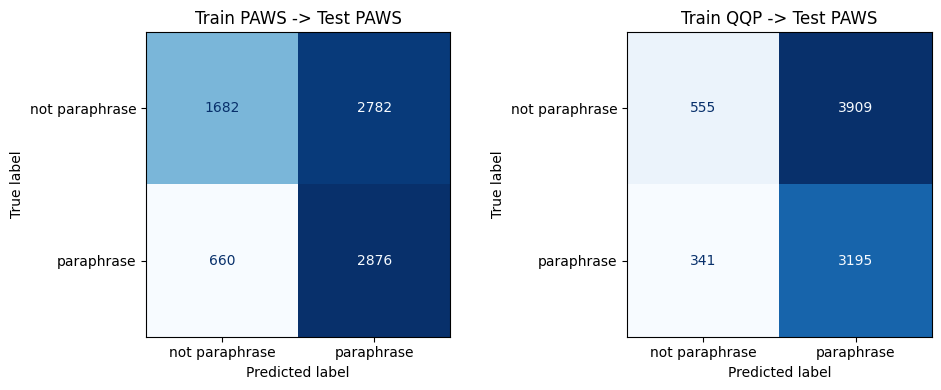

In [16]:
# Plotting confusion matrix for PAWS
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

runs = [("paws", "paws"), ("qqp", "paws")]

for i in range(len(runs)):
    train_ds, test_ds = runs[i]

    # load the saved predictions
    path = OUT + "/preds/baseline_" + train_ds + "_to_" + test_ds + ".csv"
    preds = pd.read_csv(path, keep_default_na=False)

    ConfusionMatrixDisplay.from_predictions(
        preds["label"], preds["pred"],
        display_labels=["not paraphrase", "paraphrase"],
        cmap="Blues", colorbar=False, ax=axes[i]
        )
    axes[i].set_title("Train " + train_ds.upper() + " -> Test " + test_ds.upper())

plt.tight_layout()
plt.savefig(OUT + "/figures/baseline_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Checking what the QQP model learned
# positive weight = pushes toward paraphrase, negative weight = pushes toward not paraphrase
vec, model = models["qqp"]
words = vec.get_feature_names_out()

# name every column in the same order build_features creates them:
# 3 features: cosine, jaccard, len_diff, then "diff" words, then "both" words
feature_names = ["cosine", "jaccard", "len_diff"]
for w in words:
    feature_names.append("only_in_one: " + w)
for w in words:
    feature_names.append("in_both: " + w)

weights = pd.DataFrame({"feature": feature_names, "weight": model.coef_[0]})

# the 3 overlap features are the first 3 rows
print("Overlap feature weights:")
display(weights.head(3))

print("Top 10 features pushing toward paraphrase:")
display(weights.sort_values("weight", ascending=False).head(10))

print("Top 10 features pushing toward not paraphrase:")
display(weights.sort_values("weight").head(10))

Overlap feature weights:


,feature,weight
0,cosine,0.394140
1,jaccard,3.791836
2,len_diff,-0.207357


Top 10 features pushing toward paraphrase:


,feature,weight
144594,in_both: quora,6.322724
5456,only_in_one: and why,6.271241
166237,in_both: why,6.210314
121974,in_both: india,4.932508
42019,only_in_one: know before,4.906403
35154,only_in_one: if an,4.642970
27842,only_in_one: for ias,4.597457
36798,only_in_one: in quora,4.440999
56240,only_in_one: people ask,4.278112
166279,in_both: why is,4.059037


Top 10 features pushing toward not paraphrase:


,feature,weight
101245,in_both: com,-9.875867
165171,in_both: what is,-7.226200
167478,in_both: word,-6.728913
537,only_in_one: 2015,-6.470404
158603,in_both: this,-5.730059
129560,in_both: majors,-5.619099
135939,in_both: of,-5.437289
62697,only_in_one: russia,-5.231306
155342,in_both: the,-5.217219
165005,in_both: what,-5.068104


In [18]:
# some PAWS pairs the QQP model got wrong
path = OUT + "/preds/baseline_qqp_to_paws.csv"
preds = pd.read_csv(path, keep_default_na=False)

wrong = preds[preds["label"] != preds["pred"]]
print(len(wrong), "out of", len(preds), "PAWS pairs predicted wrong")
print()

# print 5 random mistakes to see what fooled the model
examples = wrong.sample(5, random_state=SEED)

for i in range(len(examples)):
    row = examples.iloc[i]
    print("True label:", row["label"], "| Predicted:", row["pred"],
          "| P(paraphrase):", round(row["prob"], 2))
    print("A:", row["sentence1"])
    print("B:", row["sentence2"])
    print()

4250 out of 8000 PAWS pairs predicted wrong

True label: 0 | Predicted: 1 | P(paraphrase): 0.59
A: Four times between 1777 and 1860 , bells were mentioned , and three new ones were consecrated in 1861 .
B: Between 1777 and 1860 , four bells were consecrated , and in 1861 three new bells were mentioned .

True label: 0 | Predicted: 1 | P(paraphrase): 0.74
A: The public key token is used to make the assembly name unique .
B: The public key token is used to make the assembly name clear .

True label: 0 | Predicted: 1 | P(paraphrase): 0.66
A: The scope of the work was to consolidate some areas of the intonaco at the eastern end of the building and partially remove the soot and dirt .
B: The goal of the work was to remove some areas of intonaco at the eastern end of the building and to partially consolidate soot and dirt .

True label: 0 | Predicted: 1 | P(paraphrase): 0.79
A: Norman St John-Stevas wrote of him in 1955 as '' a man of excellent presence , a fine scholar `` .
B: Norman St Joh

## 7. Save the models

In [19]:
# save each trained model together with its vectorizer
for ds in models:
    vec, model = models[ds]
    path = OUT + "/models/baseline_" + ds + ".joblib"
    joblib.dump((vec, model), path)
    print("Saved", path)

Saved paraphrase/models/baseline_mrpc.joblib
Saved paraphrase/models/baseline_qqp.joblib
Saved paraphrase/models/baseline_paws.joblib
